In [1]:
import pandas as pd

In [3]:
file_path = "/content/Reviews[1].csv"
df = pd.read_csv(
    file_path,
    encoding="latin-1",
    engine="python",
    on_bad_lines="warn"
)
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [4]:
df.shape

(568454, 10)

The shape reports the number of rows and columns in the original dataset. The original dataset may be large, so the next step uses a reproducible sample to make development more manageable.

In [5]:
df_sample = df.sample(
    n=30000,
    random_state=42
)
df_sample = df_sample.reset_index(drop=True)
df_sample.shape

(30000, 10)

In [6]:
df_sample.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [7]:
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      30000 non-null  int64 
 1   ProductId               30000 non-null  object
 2   UserId                  30000 non-null  object
 3   ProfileName             30000 non-null  object
 4   HelpfulnessNumerator    30000 non-null  int64 
 5   HelpfulnessDenominator  30000 non-null  int64 
 6   Score                   30000 non-null  int64 
 7   Time                    30000 non-null  int64 
 8   Summary                 29999 non-null  object
 9   Text                    30000 non-null  object
dtypes: int64(5), object(5)
memory usage: 2.3+ MB


In [8]:
df_sample.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,165257,B000EVG8J2,A1L01D2BD3RKVO,"B. Miller ""pet person""",0,0,5,1268179200,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...
1,231466,B0000BXJIS,A3U62RE5XZDP0G,Marty,0,0,5,1298937600,great kitty treats,My cat loves these treats. If ever I can't fin...
2,427828,B008FHUFAU,AOXC0JQQZGGB6,Kenneth Shevlin,0,2,3,1224028800,COFFEE TASTE,A little less than I expected. It tends to ha...
3,433955,B006BXV14E,A3PWPNZVMNX3PA,rareoopdvds,0,1,2,1335312000,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin..."
4,70261,B007I7Z3Z0,A1XNZ7PCE45KK7,Og8ys1,0,2,5,1334707200,Great Taste . . .,and I want to congratulate the graphic artist ...


In [9]:
df_sample.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,0
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,1
Text,0


The sampled dataframe only has 1 missing value

In [10]:
df_sample.duplicated().sum()

np.int64(0)

In [11]:
print("Rating Distribution:")
print(df_sample["Score"].value_counts().sort_index())

Rating Distribution:
Score
1     2734
2     1572
3     2271
4     4263
5    19160
Name: count, dtype: int64


In [12]:
# inspect text columns

text_columns = ['Summary', 'Text']
df_sample[text_columns].head(10)

,Summary,Text
0,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...
1,great kitty treats,My cat loves these treats. If ever I can't fin...
2,COFFEE TASTE,A little less than I expected. It tends to ha...
3,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin..."
4,Great Taste . . .,and I want to congratulate the graphic artist ...
5,Lifesavers - Pineapple flavor,Please add more Pineapple flavor to your packa...
6,The Best Tea!,I absolutely love Yorkshire tea and am so glad...
7,Lady Grey a hit!,I have such a hard time finding loose tea loca...
8,Pretty good rice noodles,"Previously, I've attempted a recipe with white..."
9,Simply the best,I make pancakes or waffles every Saturday morn...


Inspecting the summary and full text helps confirm how customer feedback is represented and whether there are formatting issues. Reviews can vary in length, wording, spelling, and detail; these characteristics motivate the text-cleaning steps that follow.

In [13]:
# check length of customer reviews
df_sample['review_length'] = df_sample['Text'].fillna('').str.len()
df_sample['review_length'].describe()

,review_length
count,30000.000000
mean,434.467133
std,442.408980
min,35.000000
25%,179.000000
50%,300.000000
75%,528.000000
max,10800.000000


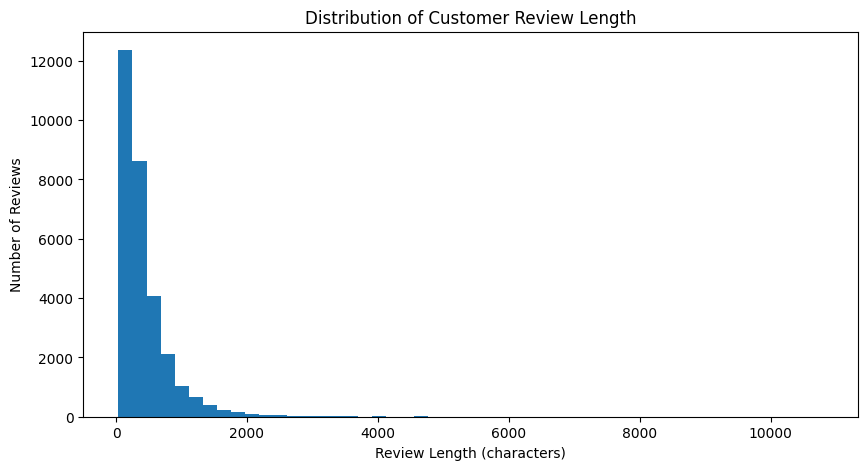

In [14]:
# visualize the distribution of the review length

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(df_sample['review_length'], bins=50)
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Customer Review Length")
plt.show()

The distribution of review length is strongly right-skewed, with most customer reviews being relatively short and a small number containing substantially longer text. These long reviews may represent outliers, but they were retained because they may contain valuable customer feedback.


In [15]:
# Create sentiment labels based on review scores

def assign_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df_sample["Sentiment"] = df_sample["Score"].apply(assign_sentiment)

# Check the sentiment distribution
print(df_sample["Sentiment"].value_counts())

Sentiment
Positive    23423
Negative     4306
Neutral      2271
Name: count, dtype: int64


In [16]:
# Display sentiment percentages

sentiment_percent = df_sample["Sentiment"].value_counts(normalize=True) * 100

print(sentiment_percent.round(2))

Sentiment
Positive    78.08
Negative    14.35
Neutral      7.57
Name: proportion, dtype: float64


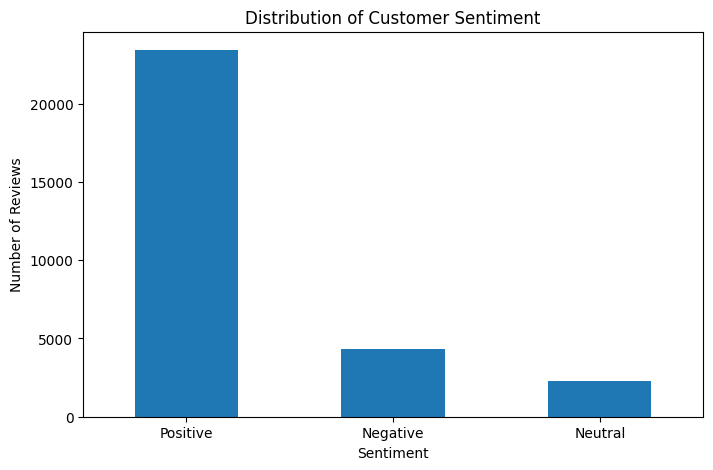

In [53]:
# Visualise sentiment distribution


df_sample["Sentiment"].value_counts().plot(kind="bar", figsize=(8, 5))

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Customer Sentiment")
plt.xticks(rotation=0)
plt.show()

The bar chart makes the class balance visible. If Positive reviews dominate, a model may achieve high accuracy while still struggling with Neutral or Negative examples. This is why the notebook later uses classification reports, macro F1, and confusion matrices to assess class-specific performance.

In [18]:
# Combine the review summary and full review text

df_sample["ReviewText"] = (
    df_sample["Summary"].fillna("") + " " +
    df_sample["Text"].fillna("")
).str.strip()

df_sample[["Summary", "Text", "ReviewText"]].head()

,Summary,Text,ReviewText
0,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...,Crunchy & Good Gluten-Free Sandwich Cookies! H...
1,great kitty treats,My cat loves these treats. If ever I can't fin...,great kitty treats My cat loves these treats. ...
2,COFFEE TASTE,A little less than I expected. It tends to ha...,COFFEE TASTE A little less than I expected. I...
3,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin...",So the Mini-Wheats were too big? First there w...
4,Great Taste . . .,and I want to congratulate the graphic artist ...,Great Taste . . . and I want to congratulate t...


The summary and full review are concatenated into one text field so that the model can use information from both. Missing values are replaced with empty strings to avoid introducing the literal word nan. This combined field becomes the main text input for cleaning and analysis.

In [19]:
# Check for completely empty reviews

empty_reviews = (df_sample["ReviewText"].str.len() == 0).sum()

print("Empty reviews:", empty_reviews)

Empty reviews: 0


In [20]:
import re

def clean_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

df_sample["CleanText"] = df_sample["ReviewText"].apply(clean_text)

df_sample[["ReviewText", "CleanText"]].head()

,ReviewText,CleanText
0,Crunchy & Good Gluten-Free Sandwich Cookies! H...,crunchy good gluten free sandwich cookies havi...
1,great kitty treats My cat loves these treats. ...,great kitty treats my cat loves these treats i...
2,COFFEE TASTE A little less than I expected. I...,coffee taste a little less than i expected it ...
3,So the Mini-Wheats were too big? First there w...,so the mini wheats were too big first there wa...
4,Great Taste . . . and I want to congratulate t...,great taste and i want to congratulate the gra...


The cleaning function converts text to lowercase, removes HTML tags and URLs, keeps letters and spaces, and standardises whitespace. This reduces superficial differences between words and removes some noise. A limitation is that punctuation, numbers, and symbols are removed, and negation words can be important for sentiment; therefore, model results should be interpreted with this preprocessing choice in mind.

In [21]:
# Compare original and cleaned review lengths

df_sample["clean_length"] = df_sample["CleanText"].str.len()

df_sample[["review_length", "clean_length"]].describe()

,review_length,clean_length
count,30000.000000,30000.000000
mean,434.467133,434.522900
std,442.408980,414.505238
min,35.000000,45.000000
25%,179.000000,191.000000
50%,300.000000,310.000000
75%,528.000000,528.000000
max,10800.000000,9987.000000


In [22]:
from sklearn.model_selection import train_test_split

X = df_sample["CleanText"]
y = df_sample["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24000
Testing samples: 6000


The sample is split into 80% training data and 20% test data. Stratification preserves approximately the same sentiment proportions in both sets.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (24000, 20000)
Testing matrix shape: (6000, 20000)


TF-IDF converts text into numeric features based on how informative words and two-word phrases are within the documents. The settings limit the vocabulary to 20,000 features.

In [24]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

y_pred_lr = logistic_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [25]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", round(accuracy_lr, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8347

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.78      0.71       861
     Neutral       0.34      0.55      0.42       454
    Positive       0.96      0.87      0.92      4685

    accuracy                           0.83      6000
   macro avg       0.65      0.73      0.68      6000
weighted avg       0.87      0.83      0.85      6000



The Logistic Regression baseline achieved 83.47% accuracy and a macro F1-score of 0.68. Performance was strongest for positive reviews (F1 = 0.92) and negative reviews (F1 = 0.71), while neutral reviews remained more challenging (F1 = 0.42), reflecting the class imbalance and ambiguity associated with neutral customer feedback.


In [26]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Linear SVM model trained successfully.")

Linear SVM model trained successfully.


In [54]:

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Accuracy:", round(accuracy_svm, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.8725

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.75      0.73       861
     Neutral       0.44      0.34      0.38       454
    Positive       0.94      0.95      0.94      4685

    accuracy                           0.87      6000
   macro avg       0.70      0.68      0.69      6000
weighted avg       0.87      0.87      0.87      6000



The SVM achieved 87.25% accuracy and a macro F1-score of 0.69. Performance was strongest for positive reviews (F1 = 0.94) and negative reviews (F1 = 0.73), while neutral reviews remained more challenging (F1 = 0.38), reflecting the class imbalance and ambiguity associated with neutral customer feedback.

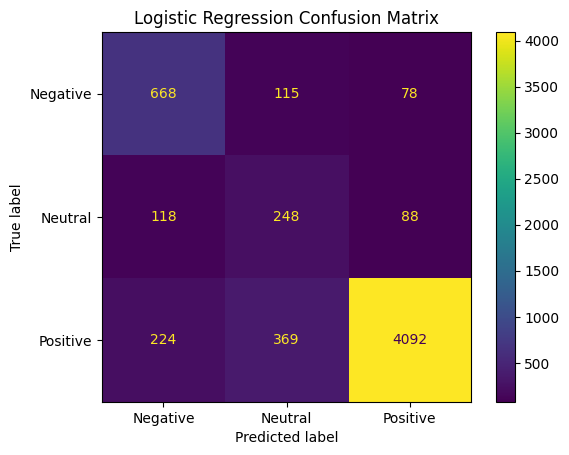

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["Negative", "Neutral", "Positive"]
)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp_lr.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

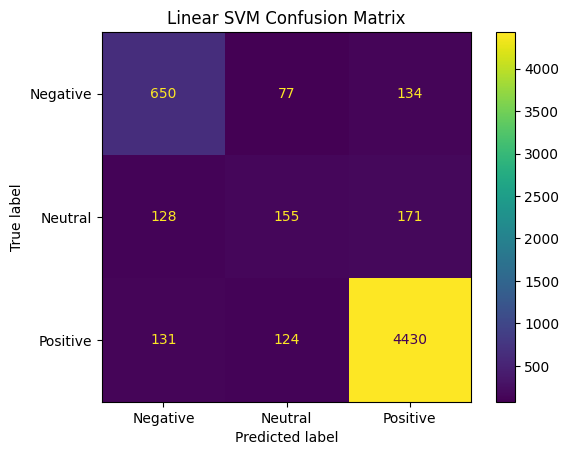

In [29]:
# Linear SVM confusion matrix
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["Negative", "Neutral", "Positive"]
)

disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp_svm.plot()
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [30]:
# Compare the two NLP models

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [accuracy_lr, accuracy_svm],
    "Macro F1": [
        0.68,
        0.69
    ]
})

model_comparison

,Model,Accuracy,Macro F1
0,Logistic Regression,0.834667,0.68
1,Linear SVM,0.872500,0.69


The Linear SVM performed better than the Logistic Regression

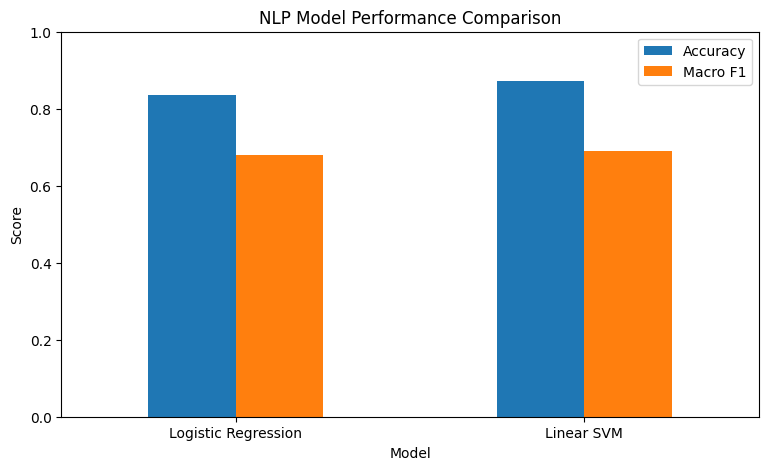

In [31]:
# Visualise model performance

model_comparison.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("NLP Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()


In [32]:
# Get TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

# Get the SVM coefficients
svm_coefficients = svm_model.coef_

print("Number of features:", len(feature_names))
print("Coefficient shape:", svm_coefficients.shape)

Number of features: 20000
Coefficient shape: (3, 20000)


In [33]:
# Check the sentiment class order
print(svm_model.classes_)

['Negative' 'Neutral' 'Positive']


In [34]:
# Extract the most influential TF-IDF features for each sentiment

for i, sentiment in enumerate(svm_model.classes_):
    coefficients = svm_coefficients[i]

    top_indices = coefficients.argsort()[-15:][::-1]

    print(f"\n===== Top features for {sentiment} sentiment =====")

    for index in top_indices:
        print(f"{feature_names[index]}: {coefficients[index]:.4f}")


===== Top features for Negative sentiment =====
disappointing: 3.6076
horrible: 3.4879
not: 3.4706
not good: 2.9608
terrible: 2.8188
yuck: 2.7475
awful: 2.6720
disappointed: 2.4492
nasty: 2.4100
very disappointed: 2.3895
disappointment: 2.3725
worst: 2.3064
bad: 2.2989
beware: 2.2149
unfortunately: 2.1920

===== Top features for Neutral sentiment =====
okay: 3.6403
three stars: 3.5730
ok: 3.4246
but: 3.4104
however: 2.5427
probably won: 2.4531
it ok: 2.4296
just ok: 2.3598
not: 2.2562
for sweet: 2.1243
at best: 2.0636
good but: 2.0413
in cold: 2.0395
ordering them: 2.0361
nothing special: 2.0278

===== Top features for Positive sentiment =====
great: 4.9356
delicious: 3.6200
best: 3.5060
excellent: 3.4123
good: 2.9984
perfect: 2.7806
yummy: 2.7530
not too: 2.7524
nice: 2.4283
awesome: 2.3569
wonderful: 2.3463
loves: 2.2793
fantastic: 2.2322
love it: 2.2089
happy: 2.1804


In [55]:
top_features = {}

for i, sentiment in enumerate(svm_model.classes_):
    coefficients = svm_coefficients[i]
    top_indices = coefficients.argsort()[-10:][::-1]

    top_features[sentiment] = pd.DataFrame({
        "Feature": feature_names[top_indices],
        "Coefficient": coefficients[top_indices]
    })

top_features

{'Negative':              Feature  Coefficient
 0      disappointing     3.607577
 1           horrible     3.487919
 2                not     3.470615
 3           not good     2.960789
 4           terrible     2.818826
 5               yuck     2.747478
 6              awful     2.672030
 7       disappointed     2.449244
 8              nasty     2.410019
 9  very disappointed     2.389460,
 'Neutral':         Feature  Coefficient
 0          okay     3.640274
 1   three stars     3.573040
 2            ok     3.424594
 3           but     3.410410
 4       however     2.542650
 5  probably won     2.453148
 6         it ok     2.429579
 7       just ok     2.359801
 8           not     2.256204
 9     for sweet     2.124306,
 'Positive':      Feature  Coefficient
 0      great     4.935632
 1  delicious     3.619973
 2       best     3.506032
 3  excellent     3.412250
 4       good     2.998355
 5    perfect     2.780640
 6      yummy     2.753002
 7    not too     2.752443
 8   

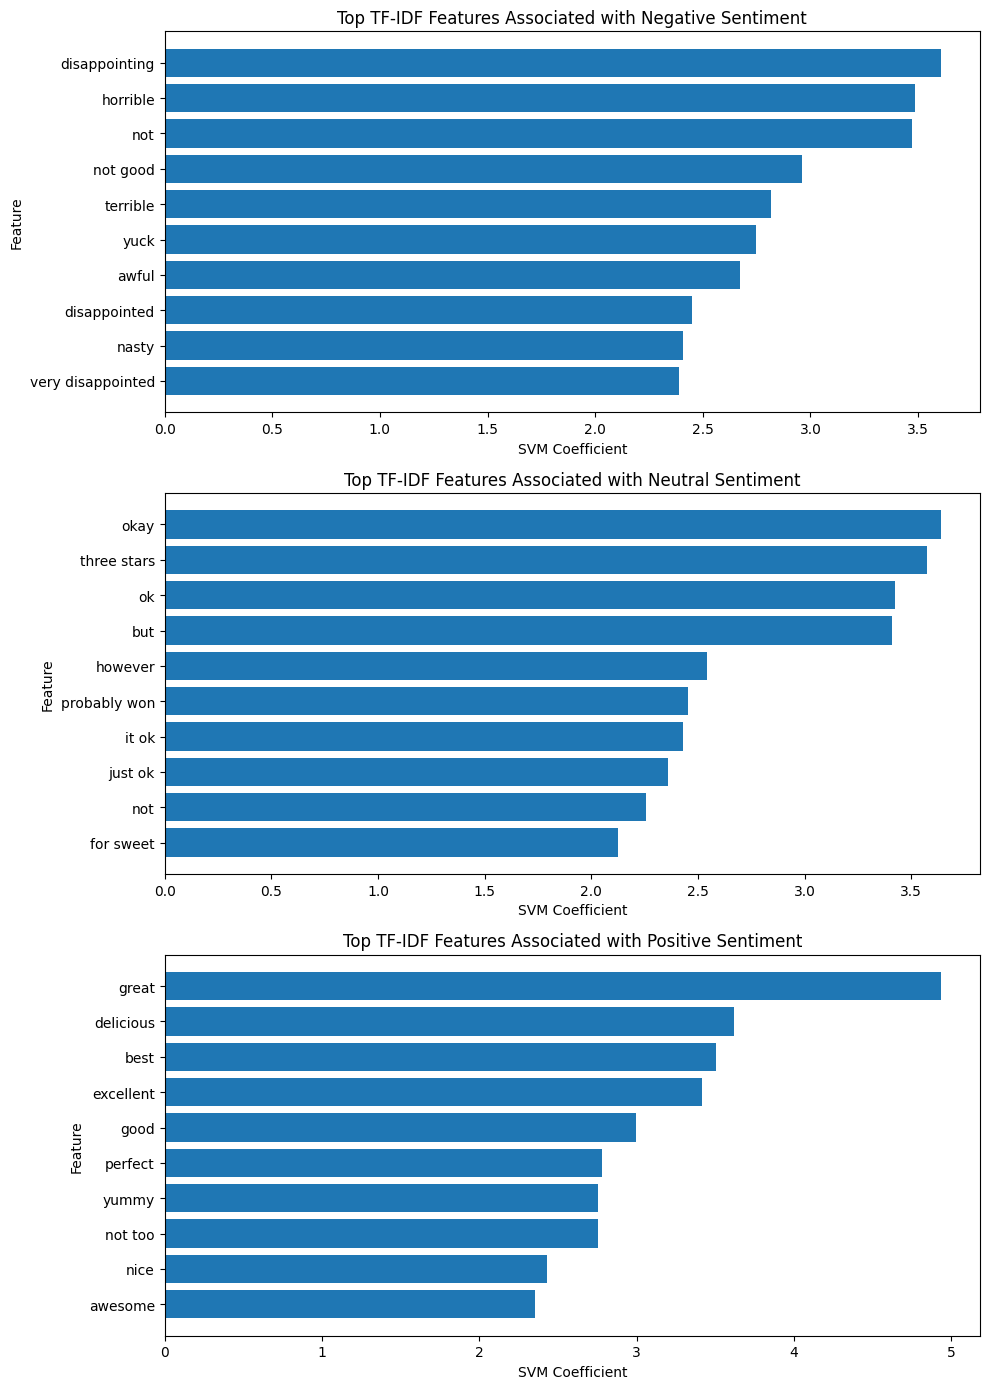

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(10, 14))

for ax, sentiment in zip(axes, svm_model.classes_):
    data = top_features[sentiment].sort_values("Coefficient")

    ax.barh(data["Feature"], data["Coefficient"])
    ax.set_title(f"Top TF-IDF Features Associated with {sentiment} Sentiment")
    ax.set_xlabel("SVM Coefficient")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrices directly from predictions
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=logistic_model.classes_)
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=svm_model.classes_)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

print("\nLinear SVM Confusion Matrix:")
print(cm_svm)

Logistic Regression Confusion Matrix:
[[ 668  115   78]
 [ 118  248   88]
 [ 224  369 4092]]

Linear SVM Confusion Matrix:
[[ 650   77  134]
 [ 128  155  171]
 [ 131  124 4430]]


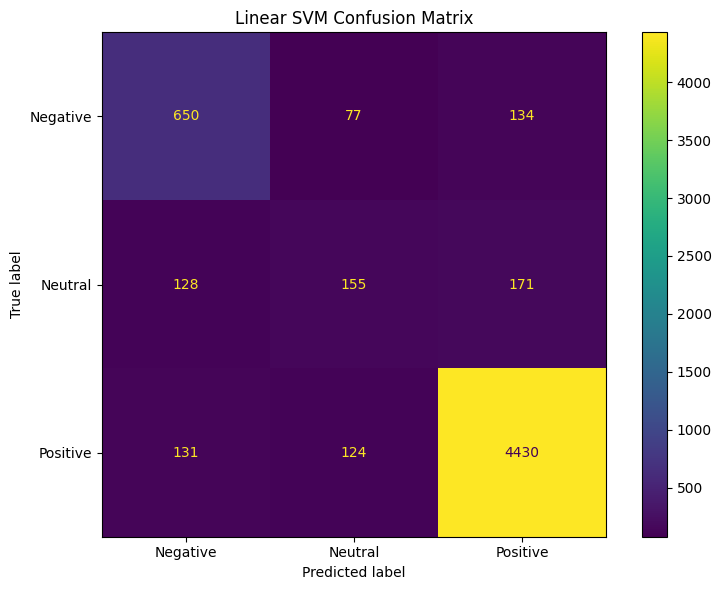

In [38]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=svm_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax)
ax.set_title("Linear SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
from collections import Counter

sentiments = ["Negative", "Neutral", "Positive"]

for sentiment in sentiments:
    text = " ".join(
        df_sample.loc[
            df_sample["Sentiment"] == sentiment,
            "CleanText"
        ]
    )

    words = text.split()
    word_counts = Counter(words)

    print(f"\n===== {sentiment} =====")
    print(word_counts.most_common(20))


===== Negative =====
[('the', 17200), ('i', 15174), ('and', 9648), ('it', 9009), ('a', 8787), ('to', 8587), ('of', 6950), ('this', 6294), ('is', 5335), ('not', 4791), ('in', 4515), ('that', 4147), ('was', 4143), ('for', 4070), ('but', 3589), ('my', 3542), ('t', 3285), ('they', 2728), ('have', 2669), ('with', 2636)]

===== Neutral =====
[('the', 10045), ('i', 8307), ('a', 6048), ('it', 5690), ('to', 4967), ('and', 4944), ('of', 4127), ('is', 3559), ('this', 3070), ('but', 2987), ('not', 2755), ('for', 2672), ('in', 2572), ('that', 2543), ('my', 1951), ('t', 1939), ('was', 1796), ('s', 1753), ('you', 1702), ('as', 1616)]

===== Positive =====
[('the', 73184), ('i', 66559), ('and', 54846), ('a', 50878), ('it', 43101), ('to', 40780), ('of', 32363), ('is', 30691), ('this', 27016), ('for', 24395), ('in', 22694), ('my', 20695), ('that', 17311), ('you', 15706), ('with', 15004), ('but', 14601), ('have', 14190), ('are', 13667), ('they', 12824), ('s', 12802)]


In [56]:
stop_words = {
    "the", "i", "and", "a", "to", "of", "it", "this", "is", "in",
    "that", "for", "was", "my", "t", "they", "have", "with", "you",
    "on", "but", "are", "as", "be", "so", "we", "me", "had", "not",
    "at", "or", "from", "all", "very", "would", "can", "there",
    "one", "just", "about", "if", "he", "she", "his", "her", "were",
    "has", "do", "did", "what", "when", "which", "who", "will",
    "get", "been", "more", "out", "up", "also", "them", "our",
    "their", "no", "than", "by", "an", "it's", "don't", "really"
}

for sentiment in sentiments:
    text = " ".join(
        df_sample.loc[
            df_sample["Sentiment"] == sentiment,
            "CleanText"
        ]
    )

    words = [
        word for word in text.split()
        if word not in stop_words and len(word) > 2
    ]

    word_counts = Counter(words)

    print(f"\n===== {sentiment} =====")
    print(word_counts.most_common(20))


===== Negative =====
[('like', 2540), ('taste', 1914), ('product', 1886), ('these', 1716), ('coffee', 1328), ('good', 1318), ('food', 1312), ('flavor', 1149), ('don', 957), ('tea', 907), ('only', 861), ('even', 860), ('other', 858), ('buy', 838), ('because', 833), ('too', 808), ('your', 804), ('amazon', 795), ('after', 771), ('some', 768)]

===== Neutral =====
[('like', 1538), ('good', 1249), ('taste', 1143), ('flavor', 967), ('these', 941), ('product', 861), ('coffee', 856), ('too', 663), ('tea', 662), ('much', 623), ('some', 615), ('other', 568), ('great', 533), ('food', 527), ('don', 505), ('little', 494), ('better', 481), ('only', 459), ('because', 444), ('price', 411)]

===== Positive =====
[('great', 11622), ('good', 10795), ('these', 10601), ('like', 10041), ('coffee', 8082), ('love', 7337), ('taste', 7043), ('tea', 6843), ('flavor', 6393), ('product', 6359), ('food', 5776), ('best', 5273), ('some', 4208), ('other', 4198), ('only', 4088), ('too', 4076), ('amazon', 3910), ('your

Removing frequent function words can make content-bearing terms more visible.

In [42]:
from sklearn.feature_extraction.text import CountVectorizer

for sentiment in sentiments:

    texts = df_sample.loc[
        df_sample["Sentiment"] == sentiment,
        "CleanText"
    ]

    vectorizer = CountVectorizer(
        stop_words=list(stop_words),
        ngram_range=(2, 3),
        min_df=10
    )

    X_ngrams = vectorizer.fit_transform(texts)

    counts = X_ngrams.sum(axis=0).A1
    features = vectorizer.get_feature_names_out()

    ngram_counts = sorted(
        zip(features, counts),
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\n===== {sentiment} =====")

    for phrase, count in ngram_counts[:20]:
        print(f"{phrase}: {count}")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['don'] not in stop_words.
  warnings.warn(



===== Negative =====
taste like: 219
tastes like: 213
don know: 166
too much: 126
gluten free: 123
dog food: 120
your money: 117
much better: 102
way too: 101
science diet: 99
don like: 97
taste good: 93
waste money: 90
after taste: 86
customer service: 85
buy again: 81
first time: 81
grocery store: 79
cup coffee: 77
expiration date: 75

===== Neutral =====
too much: 94
peanut butter: 87
buy again: 83
taste like: 82
too sweet: 82
pretty good: 68
green tea: 65
taste good: 64
tastes like: 64
don know: 60
much better: 57
gluten free: 48
grocery store: 45
these treats: 45
cup coffee: 44
dog food: 44
don like: 44
these cookies: 44
first time: 43
way too: 43

===== Positive =====
gluten free: 927
love these: 833
great product: 818
highly recommend: 802
peanut butter: 678
ve tried: 678
green tea: 676
dog food: 638
cup coffee: 549
taste like: 530
grocery store: 522
much better: 509
great price: 488
year old: 464
cat food: 453
loves these: 451
great taste: 446
these treats: 443
tastes great: 4

In [43]:
themes = {
    "Taste & flavour": [
        "taste", "flavor", "after taste", "taste like", "tastes like"
    ],
    "Product quality": [
        "great product", "product", "quality"
    ],
    "Value & price": [
        "price", "great price", "waste money", "your money"
    ],
    "Purchase intent": [
        "buy again", "highly recommend", "recommend"
    ],
    "Enjoyment": [
        "love these", "loves these", "great taste", "tastes great"
    ],
    "Dietary attributes": [
        "gluten free"
    ]
}

theme_results = []

for sentiment in sentiments:
    texts = df_sample.loc[
        df_sample["Sentiment"] == sentiment,
        "CleanText"
    ]

    combined_text = " ".join(texts)

    for theme, phrases in themes.items():
        count = sum(
            combined_text.count(phrase)
            for phrase in phrases
        )

        theme_results.append({
            "Sentiment": sentiment,
            "Theme": theme,
            "Mentions": count
        })

theme_df = pd.DataFrame(theme_results)

theme_df

,Sentiment,Theme,Mentions
0,Negative,Taste & flavour,5177
1,Negative,Product quality,2679
2,Negative,Value & price,761
3,Negative,Purchase intent,374
4,Negative,Enjoyment,73
5,Negative,Dietary attributes,123
6,Neutral,Taste & flavour,3198
7,Neutral,Product quality,1209
8,Neutral,Value & price,533
9,Neutral,Purchase intent,197


In [44]:
sentiment_counts = df_sample["Sentiment"].value_counts()

theme_df["Review_Count"] = theme_df["Sentiment"].map(sentiment_counts)

theme_df["Percentage_of_Reviews"] = (
    theme_df["Mentions"] /
    theme_df["Review_Count"] *
    100
).round(2)

theme_df

,Sentiment,Theme,Mentions,Review_Count,Percentage_of_Reviews
0,Negative,Taste & flavour,5177,4306,120.23
1,Negative,Product quality,2679,4306,62.22
2,Negative,Value & price,761,4306,17.67
3,Negative,Purchase intent,374,4306,8.69
4,Negative,Enjoyment,73,4306,1.70
5,Negative,Dietary attributes,123,4306,2.86
6,Neutral,Taste & flavour,3198,2271,140.82
7,Neutral,Product quality,1209,2271,53.24
8,Neutral,Value & price,533,2271,23.47
9,Neutral,Purchase intent,197,2271,8.67


In [45]:
theme_prevalence = []

for sentiment in sentiments:
    sentiment_df = df_sample[
        df_sample["Sentiment"] == sentiment
    ].copy()

    total_reviews = len(sentiment_df)

    for theme, phrases in themes.items():

        # Count each review only once if it contains the theme
        mask = sentiment_df["CleanText"].apply(
            lambda text: any(
                phrase in text
                for phrase in phrases
            )
        )

        review_count = int(mask.sum())

        theme_prevalence.append({
            "Sentiment": sentiment,
            "Theme": theme,
            "Reviews": review_count,
            "Percentage_of_Reviews": round(
                (review_count / total_reviews) * 100, 2
            )
        })

theme_prevalence_df = pd.DataFrame(theme_prevalence)

theme_prevalence_df

,Sentiment,Theme,Reviews,Percentage_of_Reviews
0,Negative,Taste & flavour,2100,48.77
1,Negative,Product quality,1503,34.90
2,Negative,Value & price,544,12.63
3,Negative,Purchase intent,333,7.73
4,Negative,Enjoyment,70,1.63
5,Negative,Dietary attributes,68,1.58
6,Neutral,Taste & flavour,1313,57.82
7,Neutral,Product quality,695,30.60
8,Neutral,Value & price,352,15.50
9,Neutral,Purchase intent,173,7.62


In [47]:
def analyse_review(review_text):

    prompt = f"""
You are a customer feedback analyst.

Analyse the following customer review.

Return ONLY valid JSON with these five fields:

{{
  "sentiment": "Positive, Neutral, or Negative",
  "theme": "The main theme of the review",
  "issue_or_aspect": "The specific product or customer experience being discussed",
  "customer_intent": "The customer's likely behavioural intent",
  "actionable_insight": "A concise recommendation for the business"
}}

Rules:
- Base the analysis only on the review.
- Do not invent information.
- If customer intent is unclear, use "Unclear".
- Keep each field concise.
- Sentiment should reflect the actual wording of the review.

Customer review:
"{review_text}"
"""

    response = client.responses.create(
        model="gpt-5-mini",
        input=prompt
    )

    return response.output_text

In [58]:
def extract_customer_intent(text):
    text = str(text).lower()

    # Check negative intent first
    if re.search(
        r"\b(won't buy|will not buy|wouldn't buy|never buy|"
        r"not buy|avoid|stay away)\b", text
    ):
        return "Unlikely to repurchase"

    elif re.search(
        r"\b(do not recommend|don't recommend|"
        r"not recommend|would not recommend)\b", text
    ):
        return "Unlikely to recommend"

    elif re.search(
        r"\b(buy again|purchase again|will buy|would buy|"
        r"buy more|ordering again)\b", text
    ):
        return "Likely to repurchase"

    elif re.search(
        r"\b(recommend|highly recommend|recommended)\b", text
    ):
        return "Likely to recommend"

    elif re.search(r"\b(return|refund|send back)\b", text):
        return "Potential return/refund"

    elif re.search(
        r"\b(too expensive|overpriced|expensive|"
        r"waste of money|waste money)\b", text
    ):
        return "Price-sensitive"

    elif re.search(
        r"\b(want|wanted|looking for|needed|need)\b", text
    ):
        return "Expressed need"

    else:
        return "Unclear"


In [50]:

df_sample["CustomerIntent"] = df_sample["ReviewText"].apply(
    extract_customer_intent
)

intent_counts = df_sample["CustomerIntent"].value_counts()

print("Customer intent distribution:")
print(intent_counts)

print("\nPercentages:")
print(
    (intent_counts / len(df_sample) * 100).round(2)
)


Customer intent distribution:
CustomerIntent
Unclear                    20576
Expressed need              3758
Likely to recommend         2692
Price-sensitive             1127
Unlikely to repurchase       723
Likely to repurchase         687
Potential return/refund      285
Unlikely to recommend        152
Name: count, dtype: int64

Percentages:
CustomerIntent
Unclear                    68.59
Expressed need             12.53
Likely to recommend         8.97
Price-sensitive             3.76
Unlikely to repurchase      2.41
Likely to repurchase        2.29
Potential return/refund     0.95
Unlikely to recommend       0.51
Name: count, dtype: float64


The rules assigned 20,576 reviews (68.59%) to `Unclear`, 3,758 (12.53%) to `Expressed need`, 2,692 (8.97%) to `Likely to recommend`, 1,127 (3.76%) to `Price-sensitive`, 723 (2.41%) to `Unlikely to repurchase`, 687 (2.29%) to `Likely to repurchase`, 285 (0.95%) to `Potential return/refund`, and 152 (0.51%) to `Unlikely to recommend`. The high `Unclear` share shows that the current keyword dictionary captures only a subset of how customers express intent.

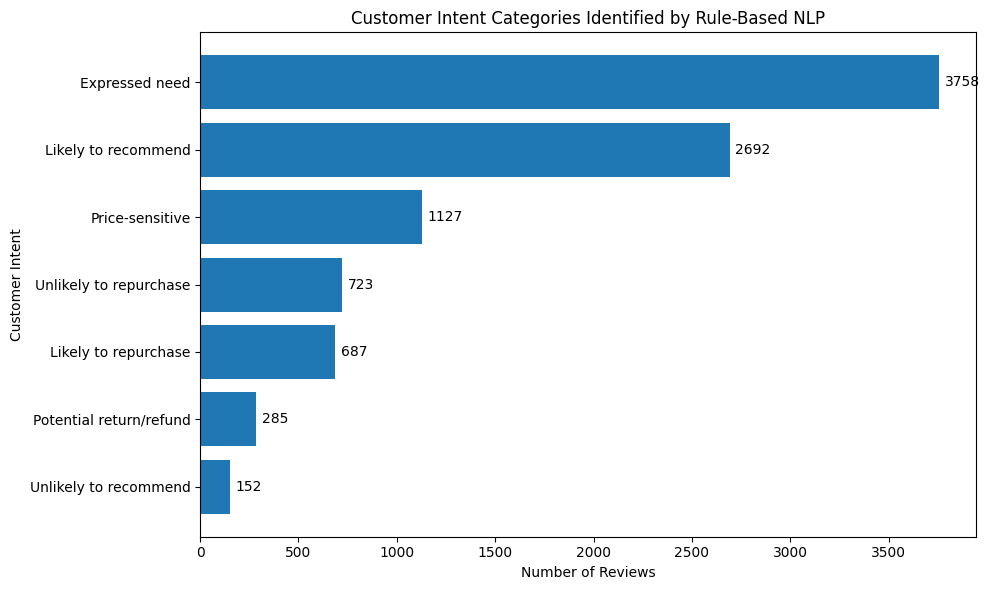

In [59]:
plot_data = intent_counts.drop("Unclear").sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_data.index, plot_data.values)

ax.bar_label(bars, fmt="%.0f", padding=4)

ax.set_title("Customer Intent Categories Identified by Rule-Based NLP")
ax.set_xlabel("Number of Reviews")
ax.set_ylabel("Customer Intent")

plt.tight_layout()
plt.show()


The chart compares the seven intent categories identified by the keyword rules, excluding Unclear so the smaller groups remain visible. Expressed need and Likely to recommend are the largest identified categories in this view, while Unlikely to recommend and Potential return/refund are less frequent.

# **Overall findings and limitations**


In this project, a replicable sample of 30,000 customer reviews is used to investigate rating-based sentiment, train and test the performance of the TF-IDF classifiers (Linear SVM and Logistic Regression), find relevant words, examine the most common phrases and themes, and estimate customer-intent categories based on explicit rules for keywords. The Linear SVM produced an 87.25% precision score in the observed evaluation, whereas the accuracy score for the Logistic Regression was 83.47%; the class-specific metrics and confusion matrices should also be taken into consideration, especially regarding Neutral reviews.

There are multiple limitations to the presented analysis. Sentiment labels are inferred based on the stars, not the annotated text; the model learns to predict the labels associated with the rating. The data sample is just a part of the dataset. Punctuation and numbers are filtered out, the theme and intent recognition are done using the manually selected keywords, and a considerable number of Unclear intent indicates that the rules do not cover all customer intents. The experiment with the OpenAI API could not be completed due to the exhausted API credits; thus, the final project does not contain any LLM-related analysis.

**Potential business value**


The presented workflow shows how unstructured customer reviews can be turned into structured data to help monitor the general sentiment patterns, detect common product themes, and prioritize areas for investigation. Before operational implementation, the method would require further validation, manual inspection of sampled predictions, improved theme and intent identification, and testing on other datasets.